# 03. MLP para Regressão — Protocolo de Dados e Baseline

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook estabelece o protocolo experimental comum a todos os experimentos da atividade e treina a rede neural de referência (*baseline*) para a regressão de `Risk_Score`.

São usadas seis variáveis preditoras (`Diabetes`, `Hypertension`, `Chest_Pain`, `ECG_Result`, `Blood_Glucose` e `Blood_Pressure_Systolic`) e uma divisão treino/teste reproduzível (80%/20%, estratificada por `Cardiovascular_Disease`, `random_state=42`). Dentro do treinamento, é separado um subconjunto de validação, usado para o *early stopping* e, nos notebooks seguintes, para a escolha dos hiperparâmetros.

A rede é um Perceptron Multicamadas (MLP) implementado em PyTorch, com saída linear e perda `nn.MSELoss`. A configuração de referência (duas camadas ocultas de 32 neurônios com ReLU, otimizador Adam com taxa de aprendizado $10^{-3}$ e *batch* de 32) é treinada com cinco sementes, para separar o efeito da configuração da variação causada pela inicialização aleatória dos pesos.

**O conjunto de teste não participa do treinamento, da seleção nem da avaliação neste notebook.** Ele é reservado para a avaliação final, feita uma única vez, depois do congelamento dos modelos (Notebooks 06 e 07).

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-03` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 03.

O código verifica a existência do dataset e dos módulos da pasta `src` e prepara o ambiente para a execução das etapas seguintes.

In [2]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

# 1. Conectar o Google Drive ao Colab
drive.mount("/content/drive")

# 2. Identificar a pasta principal do projeto
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

# 3. Verificar o dataset original e os módulos do projeto
ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"

for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"

# 4. Definir a pasta notebooks como diretório de execução
os.chdir(PROJETO / "notebooks")

# 5. Permitir a importação dos módulos da pasta src
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino

# Recarrega os módulos, caso uma versão anterior esteja em memória
for modulo in (pipeline_data, modelos_mlp, metricas, treino):
    importlib.reload(modulo)

# 6. Pastas de saída
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
pasta_curvas = PROJETO / "logs" / "curvas"
for pasta in (pasta_tabelas, pasta_figuras, pasta_curvas):
    pasta.mkdir(parents=True, exist_ok=True)

print("Projeto localizado em:", PROJETO)
print("Diretório de execução:", Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03
Diretório de execução: /content/drive/MyDrive/projeto-cardiovascular-ia-03/notebooks


### Registro do ambiente de execução

Registra-se o ambiente de execução (sistema, CPU, *threads*, RAM, versões das bibliotecas e GPU, se houver), porque os tempos de treinamento deste notebook dependem desses fatores; o registro completo e as medições de eficiência serão consolidados no Notebook 08.

In [3]:
import platform
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch

DEVICE = "cpu"   # dispositivo fixo e declarado; CPU e GPU são comparadas no Notebook 08

ambiente = {
    "Sistema operacional": platform.platform(),
    "Processador": platform.processor() or "não informado",
    "CPUs lógicas": os.cpu_count(),
    "Threads do PyTorch (torch.get_num_threads())": torch.get_num_threads(),
    "RAM total (GB)": round(psutil.virtual_memory().total / 1024**3, 2),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

,Valor
Sistema operacional,Linux-6.6.159+-x86_64-with-glibc2.39
Processador,x86_64
CPUs lógicas,2
Threads do PyTorch (torch.get_num_threads()),1
RAM total (GB),12.67
Python,3.13.18
PyTorch,2.14.1+cpu
NumPy,2.4.6
Pandas,2.2.3
scikit-learn,1.6.1


## 1. Preparação dos dados e protocolo experimental

**Justificativa do protocolo.** Existem versões já pré-processadas do dataset para os dois problemas (`dataset_regression.csv` e `dataset_classification.csv`). Nelas, porém, a imputação e o `StandardScaler` foram ajustados com os 20.000 registros, antes de qualquer divisão entre treinamento e teste. Usá-las diretamente contrariaria o princípio de ajustar o pré-processamento apenas com os dados de treino e caracterizaria *data leakage*.

Por isso, parte-se do CSV original. São preservados o dataset (as mesmas 20.000 linhas), os dois targets, as seis features e a divisão treino/teste. Apenas o pré-processamento é refeito, depois da divisão.

A divisão ocorre em dois níveis:

| Nível | Conjuntos | Critério | Uso |
|---|---|---|---|
| 1 | Treino (16.000) e teste (4.000) | 80%/20%, estratificada pela classe, `random_state=42` | Teste reservado para a avaliação final |
| 2 | Ajuste (12.800) e validação (3.200), dentro do treino | 80%/20%, estratificada pela classe, `random_state=42` | Ajuste dos pesos; validação para *early stopping* e escolha de hiperparâmetros |

Os mesmos índices são usados na classificação e na regressão, para que os dois problemas sejam treinados, validados e testados sobre os mesmos registros. A função `preparar_divisoes` compara automaticamente o resultado com valores de referência registrados para essa divisão (tamanhos, positivos, ausentes, mediana da glicose e primeiros índices) e interrompe a execução se algum deles divergir.

In [4]:
# Divisão a partir do CSV original, com verificação automática
dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")
print("Divisão conferida com os valores de referência: OK\n")

conjuntos = ["ajuste", "validacao", "teste"]
resumo_divisao = pd.DataFrame({
    "Registros": [len(dados[f"X_{c}"]) for c in conjuntos],
    "Positivos (classe 1)": [int(dados[f"y_{c}_c"].sum()) for c in conjuntos],
    "% positivos": [100 * dados[f"y_{c}_c"].mean() for c in conjuntos],
    "Glicose ausente": [int(dados[f"X_{c}"]["Blood_Glucose"].isna().sum()) for c in conjuntos],
    "Risk_Score médio": [dados[f"y_{c}_r"].mean() for c in conjuntos],
    "Risk_Score desvio": [dados[f"y_{c}_r"].std() for c in conjuntos],
    "Risk_Score ≤ 0": [int((dados[f"y_{c}_r"] <= 0).sum()) for c in conjuntos],
    "Risk_Score = 0": [int((dados[f"y_{c}_r"] == 0).sum()) for c in conjuntos],
}, index=["Ajuste", "Validação", "Teste"])

display(resumo_divisao.style.format({
    "% positivos": "{:.2f}",
    "Risk_Score médio": "{:.3f}",
    "Risk_Score desvio": "{:.3f}",
}))

# Registro auditável da divisão (sem valores transformados)
arquivo_indices = pipeline_data.salvar_indices(dados, PROJETO / "data" / "processed")
print("Índices salvos em:", arquivo_indices.relative_to(PROJETO))

Divisão conferida com os valores de referência: OK



,Registros,Positivos (classe 1),% positivos,Glicose ausente,Risk_Score médio,Risk_Score desvio,Risk_Score ≤ 0,Risk_Score = 0
Ajuste,12800,3917,30.60,360,9.825,4.204,27,1
Validação,3200,979,30.59,116,9.864,4.155,3,0
Teste,4000,1224,30.60,124,9.894,4.103,9,0


Índices salvos em: data/processed/indices_divisao.csv


Os três subconjuntos preservam a proporção de 30,6% da classe positiva, e as distribuições do `Risk_Score` ficaram próximas entre si, embora a estratificação tenha sido feita pela classe.

Os valores não positivos de `Risk_Score` aparecem nos três conjuntos, e o único valor exatamente igual a zero está no ajuste. Isso afeta o MAPE, que divide o erro pelo valor real: o efeito é discutido na Seção 3.

### 1.1 Evidência sobre a escolha do CSV original

Nas versões pré-processadas do dataset, a glicose ausente foi imputada com a mediana calculada nos 20.000 registros. A célula abaixo compara essa mediana com a mediana calculada apenas no subconjunto de ajuste.

In [5]:
base_completa = pd.read_csv("../data/raw/cardiovascular_disease_prediction.csv")

comparacao_mediana = pd.DataFrame({
    "Mediana de Blood_Glucose": [
        base_completa["Blood_Glucose"].median(),          # mediana usada nas versões pré-processadas
        dados["X_ajuste"]["Blood_Glucose"].median(),      # mediana usada neste projeto
    ]
}, index=["Base completa (20.000 registros)", "Somente ajuste (12.800 registros)"])
display(comparacao_mediana)

,Mediana de Blood_Glucose
Base completa (20.000 registros),105.0
Somente ajuste (12.800 registros),105.0


As duas medianas coincidem (105 mg/dL). Além disso, a padronização é uma transformação afim: reajustar o `StandardScaler` no treino sobre dados já padronizados produz exatamente o mesmo resultado que padronizar os dados originais. Portanto, **para as seis features utilizadas, partir do CSV original, em vez das versões pré-processadas, não altera nenhum valor numérico**; ele corrige o procedimento. A escolha continua necessária por princípio, já que a mediana das versões pré-processadas foi calculada incluindo o teste, e por razão prática: o checkpoint precisa guardar estatísticas em unidades reais (mg/dL e mmHg) para que o script de inferência receba amostras novas.

### 1.2 Pré-processamento sem vazamento de dados

Redes neurais são sensíveis à escala das entradas: features com magnitudes muito diferentes (glicose em torno de 105 mg/dL e variáveis binárias 0/1) produzem gradientes desproporcionais e dificultam a otimização. Por isso, as **seis** features são padronizadas.

A sequência, ajustada apenas nos 12.800 registros de ajuste e depois aplicada à validação (e, nos Notebooks 06 e 07, ao teste e às novas amostras), é:

1. **Codificação** binária: `No`/`Normal` = 0 e `Yes`/`Abnormal` = 1. Uma categoria desconhecida gera erro, em vez de ser aceita silenciosamente.
2. **Imputação** de `Blood_Glucose` pela mediana do ajuste. A mediana da pressão sistólica também é calculada, embora não haja ausentes, para proteger a inferência caso uma amostra nova chegue sem esse valor.
3. **`StandardScaler`** nas seis colunas: $z = (x - \mu_{\text{ajuste}}) / \sigma_{\text{ajuste}}$.

Na regressão, o alvo `Risk_Score` também é padronizado com a média e o desvio do ajuste, para estabilizar o treinamento; as previsões são convertidas de volta à escala original antes do cálculo de qualquer métrica.

Todas essas estatísticas serão gravadas no checkpoint do modelo final (Notebook 06).

In [6]:
dt = treino.preparar_dados_tarefa(dados, "regressao")   # teste não incluído
assert set(dt["X"]) == {"ajuste", "validacao"}, "O teste não deve ser transformado neste notebook."

est = dt["estatisticas"]
tabela_preprocessamento = pd.DataFrame({
    "Tipo": ["binária"] * 4 + ["contínua"] * 2,
    "Codificação / mediana de imputação": [
        f"{est['categorias'][f][0]}=0, {est['categorias'][f][1]}=1" for f in est["features"][:4]
    ] + [f"mediana = {est['mediana_imputacao'][f]:.1f}" for f in est["features"][4:]],
    "Média (ajuste)": est["x_media"],
    "Desvio (ajuste)": est["x_desvio"],
    "Média após padronização — ajuste": dt["X"]["ajuste"].mean(axis=0),
    "Desvio após padronização — ajuste": dt["X"]["ajuste"].std(axis=0),
    "Média após padronização — validação": dt["X"]["validacao"].mean(axis=0),
}, index=est["features"])
display(tabela_preprocessamento.style.format(precision=4))

# Conferências: média 0 e desvio 1 apenas no conjunto usado no ajuste
assert np.allclose(dt["X"]["ajuste"].mean(axis=0), 0, atol=1e-5)
assert np.allclose(dt["X"]["ajuste"].std(axis=0), 1, atol=1e-4)
assert dt["X"]["ajuste"].dtype == np.float32

print("Escala do alvo (ajuste): média = {y_media:.4f}, desvio = {y_desvio:.4f}".format(**dt["escala_alvo"]))
print("Alvo padronizado no ajuste: média = %.4f, desvio = %.4f"
      % (dt["y"]["ajuste"].mean(), dt["y"]["ajuste"].std()))

,Tipo,Codificação / mediana de imputação,Média (ajuste),Desvio (ajuste),Média após padronização — ajuste,Desvio após padronização — ajuste,Média após padronização — validação
Diabetes,binária,"No=0, Yes=1",0.3039,0.4599,-0.0000,1.0000,0.0119
Hypertension,binária,"No=0, Yes=1",0.2963,0.4566,-0.0000,1.0000,0.0027
Chest_Pain,binária,"No=0, Yes=1",0.2133,0.4096,-0.0000,1.0000,-0.0004
ECG_Result,binária,"Normal=0, Abnormal=1",0.2541,0.4353,0.0000,1.0001,-0.0108
Blood_Glucose,contínua,mediana = 105.0,105.5848,27.7011,-0.0000,1.0000,-0.0013
Blood_Pressure_Systolic,contínua,mediana = 125.0,124.8395,17.5930,0.0000,1.0000,-0.0051


Escala do alvo (ajuste): média = 9.8246, desvio = 4.2035
Alvo padronizado no ajuste: média = 0.0000, desvio = 1.0000


No ajuste, as médias padronizadas são 0 e os desvios são 1 por construção. Na validação, as médias ficam próximas de zero, mas não exatamente zero: isso é esperado e confirma que as estatísticas da validação **não** foram usadas no ajuste da transformação.

## 2. Arquitetura da rede

A classe `MLP` (`src/models.py`) apresenta uma sequência de camadas `nn.Linear` seguidas de ativação, com saída linear. Os hiperparâmetros (camadas, neurônios, ativação e *dropout*) são argumentos, o que permite variá-los no estudo sem reescrever o código.

**Combinação camada de saída e função de perda.** O `Risk_Score` é uma quantidade contínua, que pode assumir valores negativos. Por isso a saída tem **1 neurônio sem ativação**: uma ativação como a sigmoide ou a ReLU restringiria o intervalo de valores possíveis. A perda é o **erro quadrático médio** (`nn.MSELoss`), $L = \frac{1}{N}\sum_i (\hat{y}_i - y_i)^2$, ela penaliza mais os erros grandes, o que é coerente com o uso do RMSE como métrica principal.

**Número de parâmetros.** Para $d$ entradas, $L$ camadas ocultas de $n$ neurônios e 1 saída:

$$P = (d\,n + n) + (L-1)(n^2 + n) + (n + 1)$$

Para o baseline ($d=6$, $n=32$, $L=2$): $P = 224 + 1.056 + 33 = 1.313$.

In [7]:
rede_baseline = modelos_mlp.MLP(in_dim=6, out_dim=1, hidden=(32, 32), activation="ReLU")
print(rede_baseline)

# Parâmetros por camada (pesos + vieses)
camadas_lineares = [m for m in rede_baseline.net if isinstance(m, torch.nn.Linear)]
tabela_parametros = pd.DataFrame({
    "Camada": ["Oculta 1", "Oculta 2", "Saída"],
    "Formato": [f"Linear({m.in_features}, {m.out_features})" for m in camadas_lineares],
    "Pesos": [m.weight.numel() for m in camadas_lineares],
    "Vieses": [m.bias.numel() for m in camadas_lineares],
})
tabela_parametros["Total"] = tabela_parametros["Pesos"] + tabela_parametros["Vieses"]
display(tabela_parametros)

n_parametros = modelos_mlp.contar_parametros(rede_baseline)
print(f"Parâmetros treináveis: {n_parametros}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


,Camada,Formato,Pesos,Vieses,Total
0,Oculta 1,"Linear(6, 32)",192,32,224
1,Oculta 2,"Linear(32, 32)",1024,32,1056
2,Saída,"Linear(32, 1)",32,1,33


Parâmetros treináveis: 1313


## 3. Treinamento do baseline com cinco sementes

A configuração de referência permanece fixa como ponto de partida do estudo de hiperparâmetros (Notebook 05).

**Laço de treinamento** (`src/train.py`): a cada época, os lotes do `DataLoader` passam por `zero_grad()` → *forward* → perda → `backward()` → `step()`. Ao final da época, a perda é calculada na validação com `model.eval()` e sem gradientes. Se a perda de validação não melhorar por 20 épocas seguidas (tolerância `min_delta = 1e-6`), o treinamento é interrompido e **o estado com menor perda de validação é restaurado**.

**Sementes.** A inicialização dos pesos e a ordem dos lotes são aleatórias. Para distinguir o efeito da configuração do efeito do acaso, o baseline é treinado com as sementes 0, 1, 2, 3 e 4, fixando `random`, `numpy` e `torch`. A divisão dos dados não muda entre sementes: ela usa sempre `random_state=42`.

**Registros por semente:** número de parâmetros, época do melhor estado, épocas executadas (época de parada), tempo de treinamento e as métricas de ajuste e validação na escala original do `Risk_Score`. As curvas de perda são salvas em `logs/curvas/`.

**Convenção do desvio padrão.** O resumo entre sementes usa o desvio padrão **amostral** (`ddof=1`), porque as cinco sementes são uma amostra das inicializações possíveis. Esse desvio descreve apenas a variação causada pela inicialização com os mesmos dados; os *folds* de uma validação cruzada variam os dados, uma fonte de variação diferente, e os dois desvios não devem ser comparados diretamente.

In [8]:
config_baseline = dict(treino.CONFIG_BASELINE)
descricao_config = {
    "hidden": "Camadas ocultas (neurônios por camada)",
    "activation": "Função de ativação",
    "dropout": "Dropout",
    "otimizador": "Otimizador",
    "lr": "Taxa de aprendizado",
    "batch_size": "Tamanho do batch (treino)",
    "weight_decay": "Weight decay (L2)",
    "n_epocas": "Número máximo de épocas",
    "paciencia": "Paciência do early stopping",
    "pos_weight": "pos_weight (só classificação)",
}
display(pd.DataFrame({
    "Hiperparâmetro": [descricao_config[k] for k in config_baseline],
    "Valor": [str(v) for v in config_baseline.values()],
}))
print("Sementes:", treino.SEMENTES)

,Hiperparâmetro,Valor
0,Camadas ocultas (neurônios por camada),"(32, 32)"
1,Função de ativação,ReLU
2,Dropout,0.0
3,Otimizador,Adam
4,Taxa de aprendizado,0.001
5,Tamanho do batch (treino),32
6,Weight decay (L2),0.0
7,Número máximo de épocas,200
8,Paciência do early stopping,20
9,pos_weight (só classificação),False


Sementes: (0, 1, 2, 3, 4)


In [9]:
import json
import time

registros, historicos, modelos_treinados = [], {}, {}
inicio_total = time.perf_counter()

for semente in treino.SEMENTES:
    modelo, resultado, registro = treino.executar_configuracao(dt, {}, semente, device=DEVICE)
    assert not registro["divergiu"], f"O treinamento divergiu na semente {semente}."

    registros.append(registro)
    historicos[semente] = resultado["hist"]
    modelos_treinados[semente] = modelo

    # Curva de perda salva para os gráficos e para o relatório
    with open(pasta_curvas / f"regressao_baseline_semente{semente}.json", "w", encoding="utf-8") as f:
        json.dump({"tarefa": "regressao", "configuracao": "baseline", "semente": semente,
                   "config": {k: list(v) if isinstance(v, tuple) else v for k, v in config_baseline.items()},
                   "epoca_melhor": registro["epoca_melhor"], "hist": resultado["hist"]}, f)

    print(f"Semente {semente}: melhor época {registro['epoca_melhor']:3d} | "
          f"parada {registro['epocas_executadas']:3d} | "
          f"RMSE validação {registro['metricas_validacao']['RMSE']:.4f} | "
          f"{registro['tempo_s']:.1f} s")

print(f"\nTempo total das cinco sementes: {time.perf_counter() - inicio_total:.1f} s")

Semente 0: melhor época  13 | parada  33 | RMSE validação 2.9574 | 18.8 s
Semente 1: melhor época  22 | parada  42 | RMSE validação 2.9505 | 23.8 s
Semente 2: melhor época  18 | parada  38 | RMSE validação 2.9573 | 21.4 s
Semente 3: melhor época  12 | parada  32 | RMSE validação 2.9545 | 17.9 s
Semente 4: melhor época  41 | parada  61 | RMSE validação 2.9542 | 34.2 s

Tempo total das cinco sementes: 126.5 s


In [10]:
tabela_sementes = treino.tabela_registros(registros)
tabela_sementes["tempo_por_epoca_s"] = tabela_sementes["tempo_s"] / tabela_sementes["epocas_executadas"]

colunas_exibidas = [
    "semente", "epoca_melhor", "epocas_executadas", "tempo_s", "tempo_por_epoca_s",
    "RMSE_ajuste", "RMSE_validacao", "MAE_ajuste", "MAE_validacao",
    "R2_ajuste", "R2_validacao", "MedAE_validacao", "MAPE_%_validacao",
]
print("BASELINE DE REGRESSÃO — RESULTADO POR SEMENTE")
display(tabela_sementes[colunas_exibidas].style.format(precision=4).hide(axis="index"))

metricas_resumo = [
    "RMSE_ajuste", "RMSE_validacao", "MAE_ajuste", "MAE_validacao", "MSE_validacao",
    "R2_ajuste", "R2_validacao", "MedAE_validacao", "MAPE_%_ajuste", "MAPE_%_validacao",
    "epoca_melhor", "epocas_executadas", "tempo_s", "tempo_por_epoca_s",
]
resumo_baseline = treino.resumir_sementes(tabela_sementes, metricas_resumo)
print("\nBASELINE DE REGRESSÃO — MÉDIA E DESVIO ENTRE AS CINCO SEMENTES")
display(resumo_baseline.style.format(
    lambda v: f"{v:.3e}" if abs(v) >= 1e6 else f"{v:.4f}"
))

BASELINE DE REGRESSÃO — RESULTADO POR SEMENTE


semente,epoca_melhor,epocas_executadas,tempo_s,tempo_por_epoca_s,RMSE_ajuste,RMSE_validacao,MAE_ajuste,MAE_validacao,R2_ajuste,R2_validacao,MedAE_validacao,MAPE_%_validacao
0,13,33,18.8122,0.5701,2.9638,2.9574,2.3785,2.3809,0.5029,0.4933,2.0525,45.3536
1,22,42,23.7565,0.5656,2.9599,2.9505,2.3746,2.3723,0.5042,0.4957,2.0417,45.4236
2,18,38,21.4416,0.5643,2.9581,2.9573,2.3746,2.3814,0.5048,0.4933,2.0514,45.3550
3,12,32,17.9469,0.5608,2.9664,2.9545,2.3833,2.3808,0.5020,0.4943,2.0586,45.8269
4,41,61,34.1602,0.5600,2.9515,2.9542,2.3674,2.3749,0.5070,0.4944,2.0337,45.4757



BASELINE DE REGRESSÃO — MÉDIA E DESVIO ENTRE AS CINCO SEMENTES


,média,desvio (ddof=1),mínimo,máximo
RMSE_ajuste,2.9599,0.0057,2.9515,2.9664
RMSE_validacao,2.9548,0.0028,2.9505,2.9574
MAE_ajuste,2.3757,0.0058,2.3674,2.3833
MAE_validacao,2.3781,0.0042,2.3723,2.3814
MSE_validacao,8.7307,0.0167,8.7054,8.7460
R2_ajuste,0.5042,0.0019,0.5020,0.5070
R2_validacao,0.4942,0.0010,0.4933,0.4957
MedAE_validacao,2.0476,0.0098,2.0337,2.0586
MAPE_%_ajuste,2.211e+14,3.428e+12,2.165e+14,2.248e+14
MAPE_%_validacao,45.4870,0.1968,45.3536,45.8269


**Sobre o MAPE.** O MAPE é apresentado em percentual: o valor do scikit-learn, que é uma proporção, é multiplicado por 100. No subconjunto de ajuste, ele atinge ordens de grandeza absurdas porque o ajuste contém um `Risk_Score` exatamente igual a zero: nesse caso, o scikit-learn divide o erro por um valor mínimo (épsilon) para evitar a divisão por zero, e um único registro domina a média. Na validação, que não tem zeros mas tem valores negativos e próximos de zero, o MAPE é finito, mas ainda inflado por esses registros. Por isso o MAPE é reportado, mas **não é usado para comparar ou escolher modelos**; a métrica principal é o RMSE.

### 3.1 Referência ingênua

Para saber se a rede aprendeu algo útil, compara-se o resultado com um preditor que ignora as features e prevê sempre a média do `Risk_Score` no ajuste. Qualquer modelo útil precisa superar essa referência; por construção, ela tem R² próximo de zero.

In [11]:
media_ajuste = dt["escala_alvo"]["y_media"]
referencia_ingenua = pd.DataFrame({
    conjunto: metricas.calcular_metricas_regressao(
        dt["y_original"][conjunto],
        np.full(len(dt["y_original"][conjunto]), media_ajuste),
    )
    for conjunto in ("ajuste", "validacao")
}).T

referencia_ingenua.index = ["Ajuste", "Validação"]
print("PREDITOR INGÊNUO (sempre a média do ajuste)")
display(referencia_ingenua.style.format(lambda v: f"{v:.3e}" if abs(v) >= 1e6 else f"{v:.4f}"))

rmse_val_rede = tabela_sementes["RMSE_validacao"].mean()
rmse_val_ingenuo = referencia_ingenua.loc["Validação", "RMSE"]
print(f"Redução do RMSE de validação em relação à referência ingênua: "
      f"{100 * (1 - rmse_val_rede / rmse_val_ingenuo):.1f}%")

PREDITOR INGÊNUO (sempre a média do ajuste)


,MAE,MSE,RMSE,MAPE_%,R2,MedAE
Ajuste,3.3795,17.6692,4.2035,3.457e+14,0.0000,2.9146
Validação,3.3212,17.2629,4.1549,68.4983,-0.0001,2.8500


Redução do RMSE de validação em relação à referência ingênua: 28.9%


## 4. Curvas de aprendizado

As curvas mostram a perda (MSE no alvo padronizado) por época, no ajuste e na validação, para as cinco sementes. O marcador indica a época do melhor estado restaurado pelo *early stopping*; o treinamento continua por mais 20 épocas (paciência) antes de parar.

A perda de treino de cada época é a média dos lotes **durante** a época, com os pesos mudando a cada passo. A perda de validação é calculada ao final da época, com os pesos fixos. Por isso, nas primeiras épocas, a curva de treino pode ficar acima da de validação sem que isso indique algum problema.

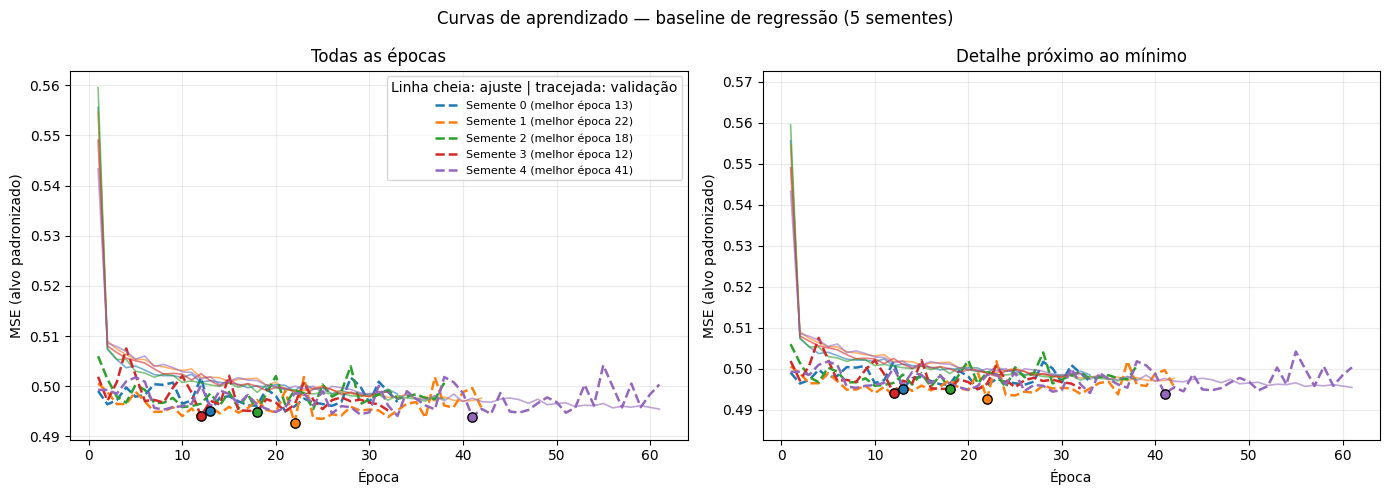

In [12]:
import matplotlib.pyplot as plt

cores = plt.cm.tab10.colors
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

for eixo, titulo in zip(eixos, ["Todas as épocas", "Detalhe próximo ao mínimo"]):
    for i, semente in enumerate(treino.SEMENTES):
        hist = historicos[semente]
        epocas = np.arange(1, len(hist["val"]) + 1)
        melhor = tabela_sementes.loc[i, "epoca_melhor"]
        eixo.plot(epocas, hist["treino"], color=cores[i], linewidth=1.2, alpha=0.6)
        eixo.plot(epocas, hist["val"], color=cores[i], linewidth=1.8, linestyle="--",
                  label=f"Semente {semente} (melhor época {melhor})")
        eixo.scatter(melhor, hist["val"][melhor - 1], color=cores[i], s=45, zorder=3,
                     edgecolor="black")
    eixo.set_title(titulo)
    eixo.set_xlabel("Época")
    eixo.set_ylabel("MSE (alvo padronizado)")
    eixo.grid(alpha=0.25)

# Zoom no eixo y em torno das perdas finais
perdas_finais = [min(h["val"]) for h in historicos.values()] + [min(h["treino"]) for h in historicos.values()]
eixos[1].set_ylim(min(perdas_finais) - 0.01, min(perdas_finais) + 0.08)
eixos[0].legend(title="Linha cheia: ajuste | tracejada: validação", fontsize=8)

fig.suptitle("Curvas de aprendizado — baseline de regressão (5 sementes)")
fig.tight_layout()
fig.savefig(pasta_figuras / "regressao_baseline_curvas.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Valores reais e previstos na validação

Para examinar **como** a rede erra, utiliza-se a semente cujo RMSE de validação é a mediana das cinco, uma escolha representativa que não favorece a melhor nem a pior inicialização. As previsões são convertidas de volta à escala original do `Risk_Score`.

Estes gráficos usam a validação, e não o teste: são um diagnóstico do baseline. Os gráficos de resíduos do modelo final, no teste, ficam no Notebook 07.

Semente com RMSE de validação mediano: 3


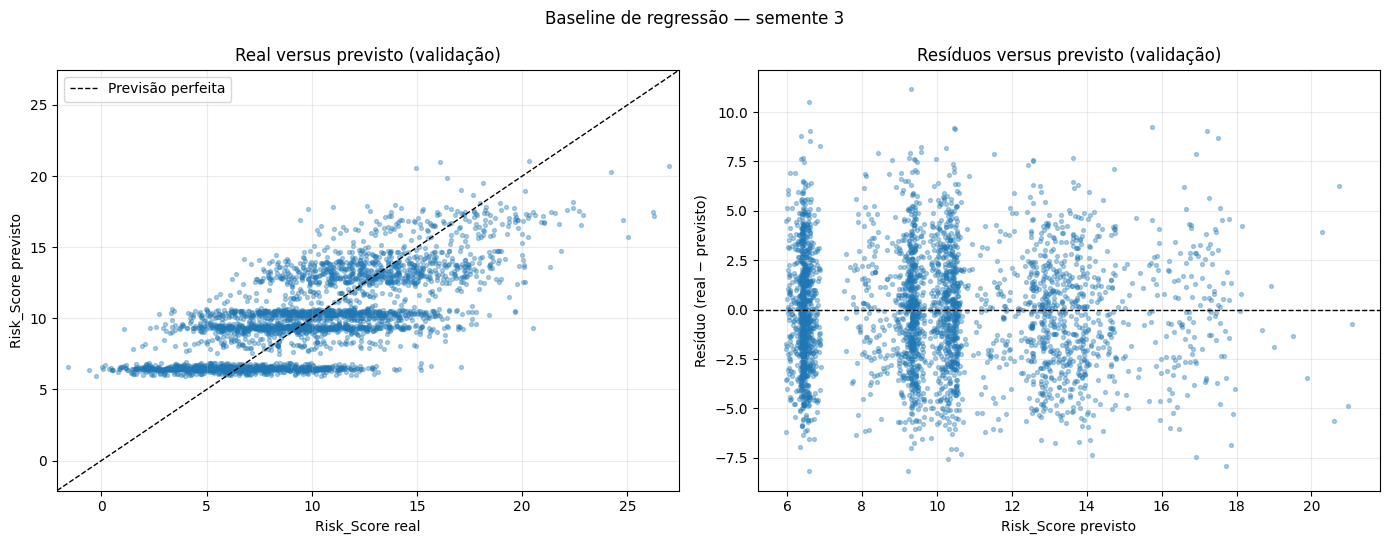

Resíduo médio: -0.0810 | desvio dos resíduos: 2.9534
Amplitude prevista: 5.97 a 21.07 | amplitude real: -1.61 a 26.97


In [13]:
ordem = tabela_sementes.sort_values("RMSE_validacao").reset_index(drop=True)
semente_mediana = int(ordem.loc[len(ordem) // 2, "semente"])
print("Semente com RMSE de validação mediano:", semente_mediana)

saida = treino.prever(modelos_treinados[semente_mediana], dt["X"]["validacao"], DEVICE)
y_prev = pipeline_data.despadronizar_alvo(saida, dt["escala_alvo"])
y_real = dt["y_original"]["validacao"]
residuos = y_real - y_prev   # real menos previsto

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

eixos[0].scatter(y_real, y_prev, s=8, alpha=0.35)
limites = [min(y_real.min(), y_prev.min()) - 0.5, max(y_real.max(), y_prev.max()) + 0.5]
eixos[0].plot(limites, limites, color="black", linestyle="--", linewidth=1, label="Previsão perfeita")
eixos[0].set_xlim(limites); eixos[0].set_ylim(limites)
eixos[0].set_xlabel("Risk_Score real"); eixos[0].set_ylabel("Risk_Score previsto")
eixos[0].set_title("Real versus previsto (validação)")
eixos[0].legend(); eixos[0].grid(alpha=0.25)

eixos[1].scatter(y_prev, residuos, s=8, alpha=0.35)
eixos[1].axhline(0, color="black", linestyle="--", linewidth=1)
eixos[1].set_xlabel("Risk_Score previsto"); eixos[1].set_ylabel("Resíduo (real − previsto)")
eixos[1].set_title("Resíduos versus previsto (validação)")
eixos[1].grid(alpha=0.25)

fig.suptitle(f"Baseline de regressão — semente {semente_mediana}")
fig.tight_layout()
fig.savefig(pasta_figuras / "regressao_baseline_real_previsto_validacao.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Resíduo médio: {residuos.mean():.4f} | desvio dos resíduos: {residuos.std():.4f}")
print(f"Amplitude prevista: {y_prev.min():.2f} a {y_prev.max():.2f} "
      f"| amplitude real: {y_real.min():.2f} a {y_real.max():.2f}")

## 6. Generalização do baseline

**Definição e sinal.** O gap segue a fórmula: desempenho no treino menos desempenho fora do treino. Aqui ele é calculado entre ajuste e validação:

$$\text{Gap} = \text{métrica}_{\text{ajuste}} - \text{métrica}_{\text{validação}}$$

A leitura do sinal depende do tipo de métrica:

- **R² (qualidade, maior é melhor):** gap positivo significa desempenho pior na validação.
- **RMSE e MAE (erro, menor é melhor):** como a fórmula é ajuste menos validação, um erro **maior na validação** produz gap **negativo**. Gap positivo significa erro menor na validação.

**Referências para a leitura.** Ajuste e validação são amostras diferentes, então mesmo um modelo incapaz de sobreajustar apresenta algum gap. Por isso, o gap da rede é apresentado ao lado de duas referências descritivas:

1. o **gap do preditor ingênuo** (Seção 3.1), que não aprende nada com as features e, portanto, não pode sobreajustar. O gap dele mostra a **ordem de grandeza** das diferenças produzidas apenas pela composição das duas amostras. Ele é usado como escala, e não subtraído do gap da rede: o RMSE do ingênuo depende da variação do próprio `Risk_Score` em cada conjunto, enquanto o RMSE da rede depende da variação dos resíduos, e as duas não precisam mudar da mesma forma entre os conjuntos;
2. a **variação entre sementes**, mostrada pelos gaps de cada semente e pelo desvio padrão do RMSE de validação.

**Limite desta análise.** Essas referências formam um **indício heurístico**, e não um teste estatístico. O desvio entre cinco sementes mede apenas a variação causada pela inicialização dos pesos e pela ordem dos lotes, e não a incerteza devida à amostragem dos registros. Por isso, ele não serve como limiar formal para declarar sobreajuste. A leitura é qualitativa:

- um gap negativo no RMSE (erro maior na validação), consistente nas cinco sementes e de magnitude **maior** que a diferença observada no ingênuo, seria um **sinal compatível** com sobreajuste;
- um gap de magnitude igual ou menor que a do ingênuo, ou com sinal que varia entre sementes, **não sustenta** essa conclusão: diferenças desse tamanho aparecem mesmo sem aprendizado.

O diagnóstico final de generalização usa também a curva de aprendizado (Seção 4), o K-fold e o teste do modelo final (Notebook 07).

O diagnóstico de *underfitting* não pode ser feito apenas com o baseline: ele exige comparar capacidades diferentes, o que é feito no estudo de neurônios e camadas (Notebook 05) e na análise das configurações extremas (Notebook 07).

In [14]:
gap_rmse_ingenuo = referencia_ingenua.loc["Ajuste", "RMSE"] - referencia_ingenua.loc["Validação", "RMSE"]

tabela_gap = pd.DataFrame({
    "semente": tabela_sementes["semente"],
    "Gap RMSE (ajuste − validação)": tabela_sementes["RMSE_ajuste"] - tabela_sementes["RMSE_validacao"],
    "Gap MAE (ajuste − validação)": tabela_sementes["MAE_ajuste"] - tabela_sementes["MAE_validacao"],
    "Gap R² (ajuste − validação)": tabela_sementes["R2_ajuste"] - tabela_sementes["R2_validacao"],
})
display(tabela_gap.style.format(precision=4).hide(axis="index"))

gaps_rmse = tabela_gap["Gap RMSE (ajuste − validação)"]
resumo_gap = pd.Series({
    "Gap RMSE do preditor ingênuo (referência)": gap_rmse_ingenuo,
    "Gap RMSE da rede — média das sementes": gaps_rmse.mean(),
    "Gap RMSE da rede — desvio entre sementes (ddof=1)": gaps_rmse.std(ddof=1),
    "Gap RMSE da rede — mínimo": gaps_rmse.min(),
    "Gap RMSE da rede — máximo": gaps_rmse.max(),
    "RMSE de validação — desvio entre sementes (ddof=1)": tabela_sementes["RMSE_validacao"].std(ddof=1),
    "Sementes com gap RMSE negativo (erro maior na validação)": int((gaps_rmse < 0).sum()),
}, name="Valor", dtype=object)   # object: mantém a contagem como inteiro
display(resumo_gap.to_frame().style.format(lambda v: f"{v:+.4f}" if isinstance(v, float) else f"{v}"))
print("Leitura heurística, não um teste estatístico (ver o texto acima).")

semente,Gap RMSE (ajuste − validação),Gap MAE (ajuste − validação),Gap R² (ajuste − validação)
0,0.0064,-0.0023,0.0096
1,0.0094,0.0023,0.0085
2,0.0008,-0.0067,0.0114
3,0.0118,0.0025,0.0077
4,-0.0026,-0.0075,0.0126


,Valor
Gap RMSE do preditor ingênuo (referência),+0.0486
Gap RMSE da rede — média das sementes,+0.0051
Gap RMSE da rede — desvio entre sementes (ddof=1),+0.0060
Gap RMSE da rede — mínimo,-0.0026
Gap RMSE da rede — máximo,+0.0118
RMSE de validação — desvio entre sementes (ddof=1),+0.0028
Sementes com gap RMSE negativo (erro maior na validação),1


Leitura heurística, não um teste estatístico (ver o texto acima).


## 7. Exportação dos resultados

As tabelas são salvas em `reports/tables`, sem arredondamento, e serão usadas no estudo de hiperparâmetros (o baseline é o valor de referência de cada gráfico) e no relatório. As curvas de perda de cada semente já foram salvas em `logs/curvas/`.

In [15]:
tabelas = {
    "regressao_baseline_sementes.csv": tabela_sementes,
    "regressao_baseline_resumo.csv": resumo_baseline.rename_axis("Indicador").reset_index(),
    "regressao_baseline_gap.csv": tabela_gap,
    "regressao_baseline_gap_resumo.csv": resumo_gap.rename_axis("Indicador").reset_index(),
    "regressao_referencia_ingenua.csv": referencia_ingenua.rename_axis("Conjunto").reset_index(),
    "divisao_resumo.csv": resumo_divisao.rename_axis("Conjunto").reset_index(),
    "preprocessamento_estatisticas.csv": tabela_preprocessamento.rename_axis("Feature").reset_index(),
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))

print("\nFiguras:")
for nome in ["regressao_baseline_curvas.png", "regressao_baseline_real_previsto_validacao.png"]:
    assert (pasta_figuras / nome).is_file()
    print("Salvo:", (pasta_figuras / nome).relative_to(PROJETO))

Salvo: reports/tables/regressao_baseline_sementes.csv
Salvo: reports/tables/regressao_baseline_resumo.csv
Salvo: reports/tables/regressao_baseline_gap.csv
Salvo: reports/tables/regressao_baseline_gap_resumo.csv
Salvo: reports/tables/regressao_referencia_ingenua.csv
Salvo: reports/tables/divisao_resumo.csv
Salvo: reports/tables/preprocessamento_estatisticas.csv

Figuras:
Salvo: reports/figures/regressao_baseline_curvas.png
Salvo: reports/figures/regressao_baseline_real_previsto_validacao.png


## 8. Síntese

**Aprendizado.** O baseline reduz o RMSE de validação em cerca de 29% em relação ao preditor ingênuo, de aproximadamente 4,15 para 2,95, e obtém $R^2$ de validação próximo de 0,49. Isso indica que as seis features contêm informação útil para prever o `Risk_Score`, embora uma parte considerável de sua variação permaneça sem explicação. Os valores exatos por semente estão nas tabelas da Seção 3.

**Estabilidade entre sementes.** As métricas de validação são muito próximas entre as cinco inicializações, com variação na terceira casa decimal do RMSE. Já a época do melhor estado varia mais. Isso é compatível com a hipótese de que as execuções atinjam regiões de desempenho semelhante, embora em épocas diferentes. Portanto, a época do melhor estado é interpretada como indicador do percurso de otimização, e não como medida isolada da qualidade da configuração.

**Generalização.** O gap de RMSE entre ajuste e validação é pequeno e muda de sinal entre as sementes. O gap de $R^2$ é positivo em todas elas, mas isso não corresponde a um aumento equivalente do erro: o MSE é semelhante nos dois conjuntos, e a diferença de $R^2$ acompanha a variância menor do `Risk_Score` na validação. Em conjunto, os resultados não mostram evidência consistente de sobreajuste neste baseline. A avaliação de subajuste depende da comparação com arquiteturas de capacidades diferentes e será feita no estudo de hiperparâmetros.

**Padrão dos erros.** Na semente de RMSE de validação mediano, as previsões ocupam uma faixa mais estreita que os valores reais. Consequentemente, os valores reais mais altos que a maior previsão são necessariamente subestimados, e os mais baixos que a menor previsão são necessariamente superestimados. Esse padrão é compatível com previsões menos extremas que os alvos, e sua relevância deve ser avaliada junto ao gráfico de resíduos e às métricas. O resíduo médio é pequeno em relação à dispersão dos resíduos, sem indicação clara de viés médio relevante.

**MAPE.** O MAPE é extremamente elevado no ajuste, que contém um `Risk_Score` igual a zero, e também fica inflado na validação devido a valores próximos de zero. A métrica é reportada para completude, mas não é usada para orientar as comparações entre modelos.

**Implicações para o estudo de hiperparâmetros.** A pequena variação observada entre as sementes sugere que diferenças entre configurações devem ser avaliadas com cuidado, usando as mesmas sementes e considerando a variação entre execuções. Diferenças de centésimos no RMSE podem ser relevantes, mas não devem ser tratadas como conclusivas apenas com base no baseline. A hipótese de que o desempenho seja limitado pela informação disponível nas seis features, e não pela capacidade da rede, será examinada no estudo de neurônios e camadas.